# *Import **Libraries***

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error


print("hi")

hi


# ***Model 1***
## ***Linear regression* Model**

1. read the data
2. do some EDA (Exploratory Data Analysis)

In [29]:
df = pd.read_csv("Car details v3.csv")
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [30]:
df.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [31]:
print(df.columns)
df.shape

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats'],
      dtype='str')


(8128, 13)

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


### delete the *null* values less than 5%

In [33]:
print(df.isna().sum())
# 5% of the data is 8128 * 5% 
print(0.05 * 8128)

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64
406.40000000000003


In [34]:
df.dropna(inplace=True)
df.info()

<class 'pandas.DataFrame'>
Index: 7906 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           7906 non-null   str    
 1   year           7906 non-null   int64  
 2   selling_price  7906 non-null   int64  
 3   km_driven      7906 non-null   int64  
 4   fuel           7906 non-null   str    
 5   seller_type    7906 non-null   str    
 6   transmission   7906 non-null   str    
 7   owner          7906 non-null   str    
 8   mileage        7906 non-null   str    
 9   engine         7906 non-null   str    
 10  max_power      7906 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7906 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


#### Some of the data types are wrong 
we should convert **mileage, max power, seats** to integers


we should also make dummy values for some of the features like the ***fuel* and the *seller type***


In [35]:
df[["max_power_value", "max_power_unit"]] = df["max_power"].str.split(" ", expand=True)
df[["engine_value", "engine_unit"]] = df["engine"].str.split(" ", expand=True)
df[["mileage_value", "mileage_unit"]] = df["mileage"].str.split(" ", expand=True)
df["seats"] = df["seats"].astype(int)

# df["mileage"].str.replace("kmpl", "").str.strip().astype(float)
# it's not working because there is a mix betweeen kmpl and km/kg


In [36]:
df["max_power_value"].dtype

<StringDtype(na_value=nan)>

name               87
year               87
selling_price      87
km_driven          87
fuel               87
seller_type        87
transmission       87
owner              87
mileage            87
engine             87
max_power          87
torque             87
seats              87
max_power_value    87
max_power_unit     87
engine_value       87
engine_unit        87
mileage_value      87
mileage_unit       87
dtype: int64

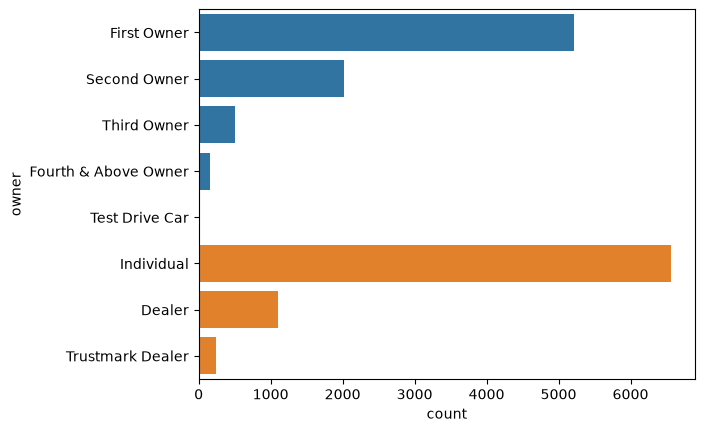

In [37]:
sns.countplot(data=df['owner'])
sns.countplot(data=df['seller_type'])

df[df["mileage_unit"] == "km/kg"].count()


<Axes: xlabel='count', ylabel='max_power_unit'>

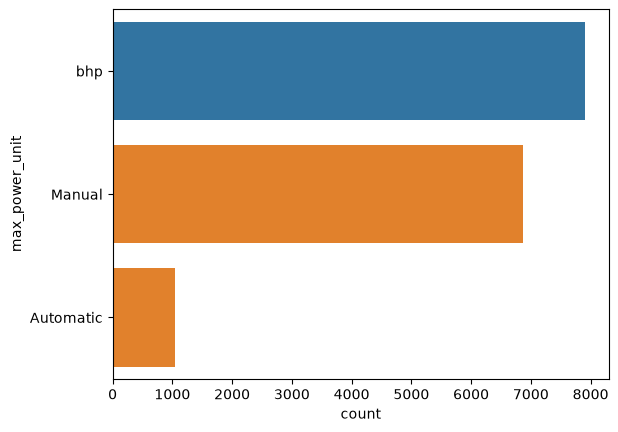

In [38]:
sns.countplot(data=df['max_power_unit'])
sns.countplot(data=df['transmission'])


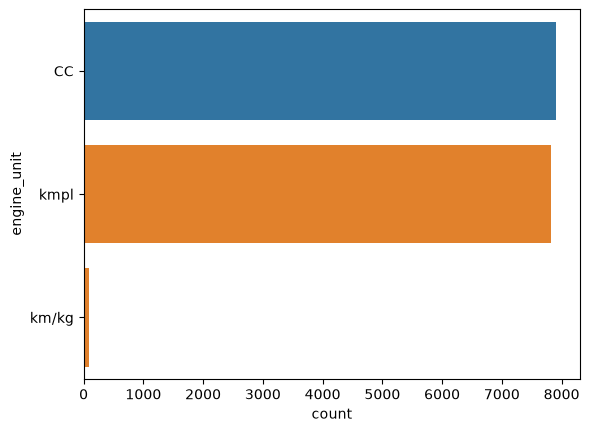

In [39]:
sns.countplot(data=df['engine_unit'])
sns.countplot(data=df['mileage_unit'])
# we can remove the max power unit and the engine unit safely
# because km/kg is less than 5%, we will remove it also
df = df[df["mileage_unit"] != "km/kg"]
df = df.drop(columns=["engine_unit", "max_power_unit", "mileage_unit", "mileage", "engine", "max_power"])
# we can also start droping columns that wont help us
# name is irrelevant, and engine and max power is now not useful and torque can't be processed easily 
df = df.drop(columns= ["name", "torque"])

In [40]:
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,max_power_value,engine_value,mileage_value
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,5,74,1248,23.4
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,5,103.52,1498,21.14
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,5,78,1497,17.7
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,5,90,1396,23.0
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,5,88.2,1298,16.1


### now we want dummy values without **unnecessary** columns

In [41]:
df = pd.get_dummies(df, columns=["transmission", "seller_type", "owner", "fuel"], dtype=int)
df["seats"] = df["seats"].astype(int)

In [42]:
# we can remove transmission automatic because we can get the same info from transmission manual since there are only two cases
# same thing with fuel petrol, same info from fuel diesel

df = df.drop(columns= ["transmission_Automatic", "fuel_Petrol"])
df.head()

,year,selling_price,km_driven,seats,max_power_value,engine_value,mileage_value,transmission_Manual,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,fuel_Diesel
0,2014,450000,145500,5,74,1248,23.4,1,0,1,0,1,0,0,0,0,1
1,2014,370000,120000,5,103.52,1498,21.14,1,0,1,0,0,0,1,0,0,1
2,2006,158000,140000,5,78,1497,17.7,1,0,1,0,0,0,0,0,1,0
3,2010,225000,127000,5,90,1396,23.0,1,0,1,0,1,0,0,0,0,1
4,2007,130000,120000,5,88.2,1298,16.1,1,0,1,0,1,0,0,0,0,0


In [43]:
df[["max_power_value", "engine_value", "mileage_value"]] = df[["max_power_value", "engine_value", "mileage_value"]].astype(float)
df.info()

<class 'pandas.DataFrame'>
Index: 7819 entries, 0 to 8127
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   year                          7819 non-null   int64  
 1   selling_price                 7819 non-null   int64  
 2   km_driven                     7819 non-null   int64  
 3   seats                         7819 non-null   int64  
 4   max_power_value               7819 non-null   float64
 5   engine_value                  7819 non-null   float64
 6   mileage_value                 7819 non-null   float64
 7   transmission_Manual           7819 non-null   int64  
 8   seller_type_Dealer            7819 non-null   int64  
 9   seller_type_Individual        7819 non-null   int64  
 10  seller_type_Trustmark Dealer  7819 non-null   int64  
 11  owner_First Owner             7819 non-null   int64  
 12  owner_Fourth & Above Owner    7819 non-null   int64  
 13  owner_Second Owner 

## let's see the heatmap!

<Axes: >

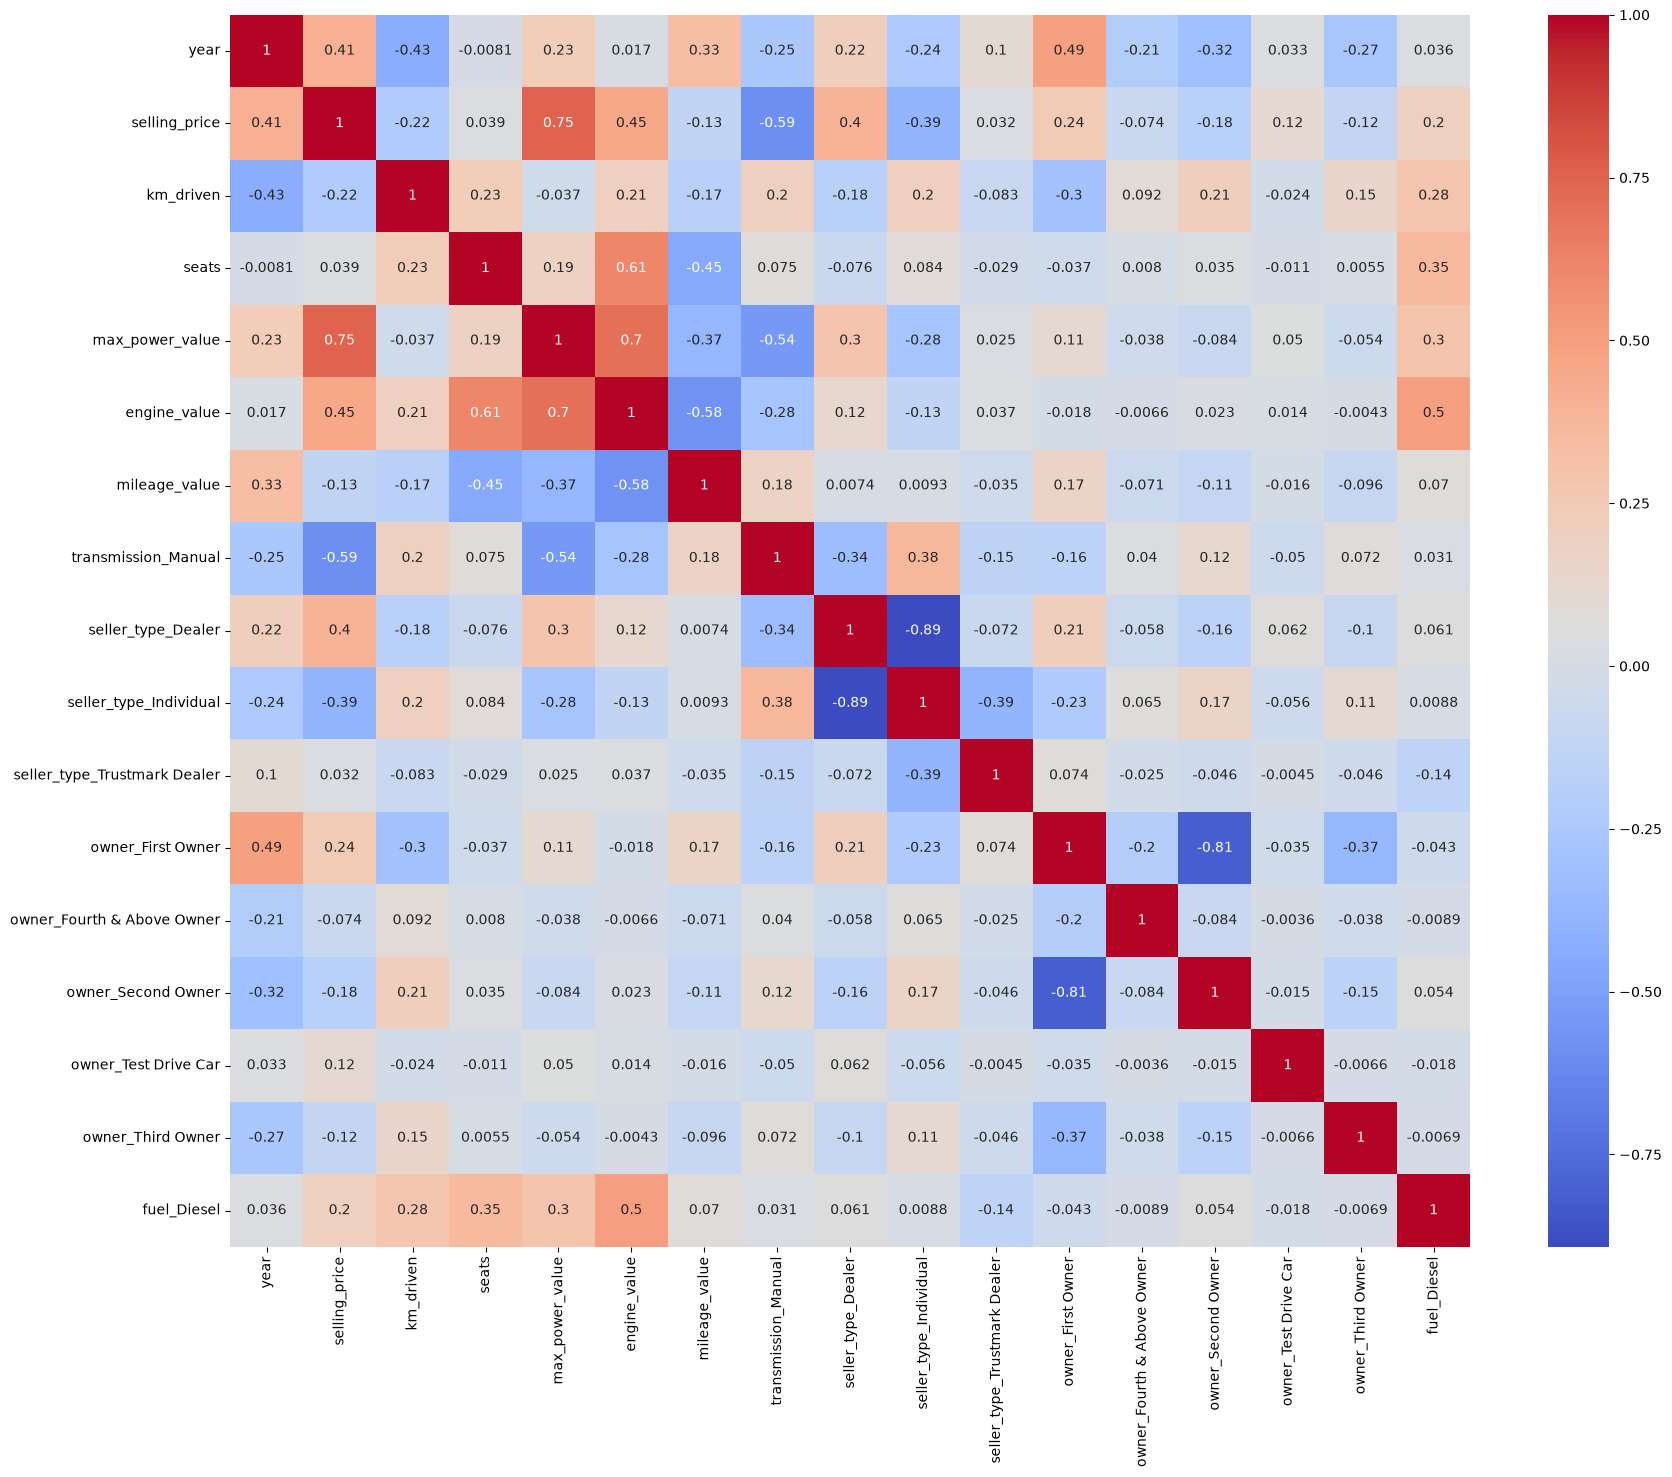

In [44]:
plt.figure(figsize=(20, 16))
sns.heatmap(data=df.corr(numeric_only=True), annot=True, cmap="coolwarm")

## let's see if there are any major ***outliers***

In [45]:
df.describe()

,year,selling_price,km_driven,seats,max_power_value,engine_value,mileage_value,transmission_Manual,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,fuel_Diesel
count,7819.000000,7.819000e+03,7.819000e+03,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000,7819.000000
mean,2013.990280,6.539858e+05,6.912583e+04,5.421281,91.935226,1463.090677,19.390375,0.866863,0.141450,0.828367,0.030183,0.660570,0.020207,0.254252,0.000639,0.064330,0.549815
std,3.865268,8.170529e+05,5.687384e+04,0.962876,35.770104,504.655439,4.001777,0.339745,0.348508,0.377085,0.171101,0.473546,0.140717,0.435468,0.025281,0.245356,0.497544
min,1994.000000,2.999900e+04,1.000000e+03,2.000000,34.200000,624.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2012.000000,2.700000e+05,3.400000e+04,5.000000,69.000000,1197.000000,16.780000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2015.000000,4.550000e+05,6.000000e+04,5.000000,82.400000,1248.000000,19.300000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,2017.000000,6.950000e+05,9.600000e+04,5.000000,102.000000,1582.000000,22.320000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000,400.000000,3604.000000,42.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [46]:
# we will remove outliers 1.5 IQR away from Q1 and Q3

def clean(df, feature) :
    df[[feature]].describe()
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1
    df = df[(df[feature] >= Q1 - 1.5*IQR)]
    df = df[(df[feature] <= Q3 + 1.5*IQR)]
    return df

df = clean(df, "selling_price")
df = clean(df, "max_power_value")
df = clean(df, "engine_value")
df = clean(df, "mileage_value")
df = df[df['seats'] < 14]
    

<Axes: >

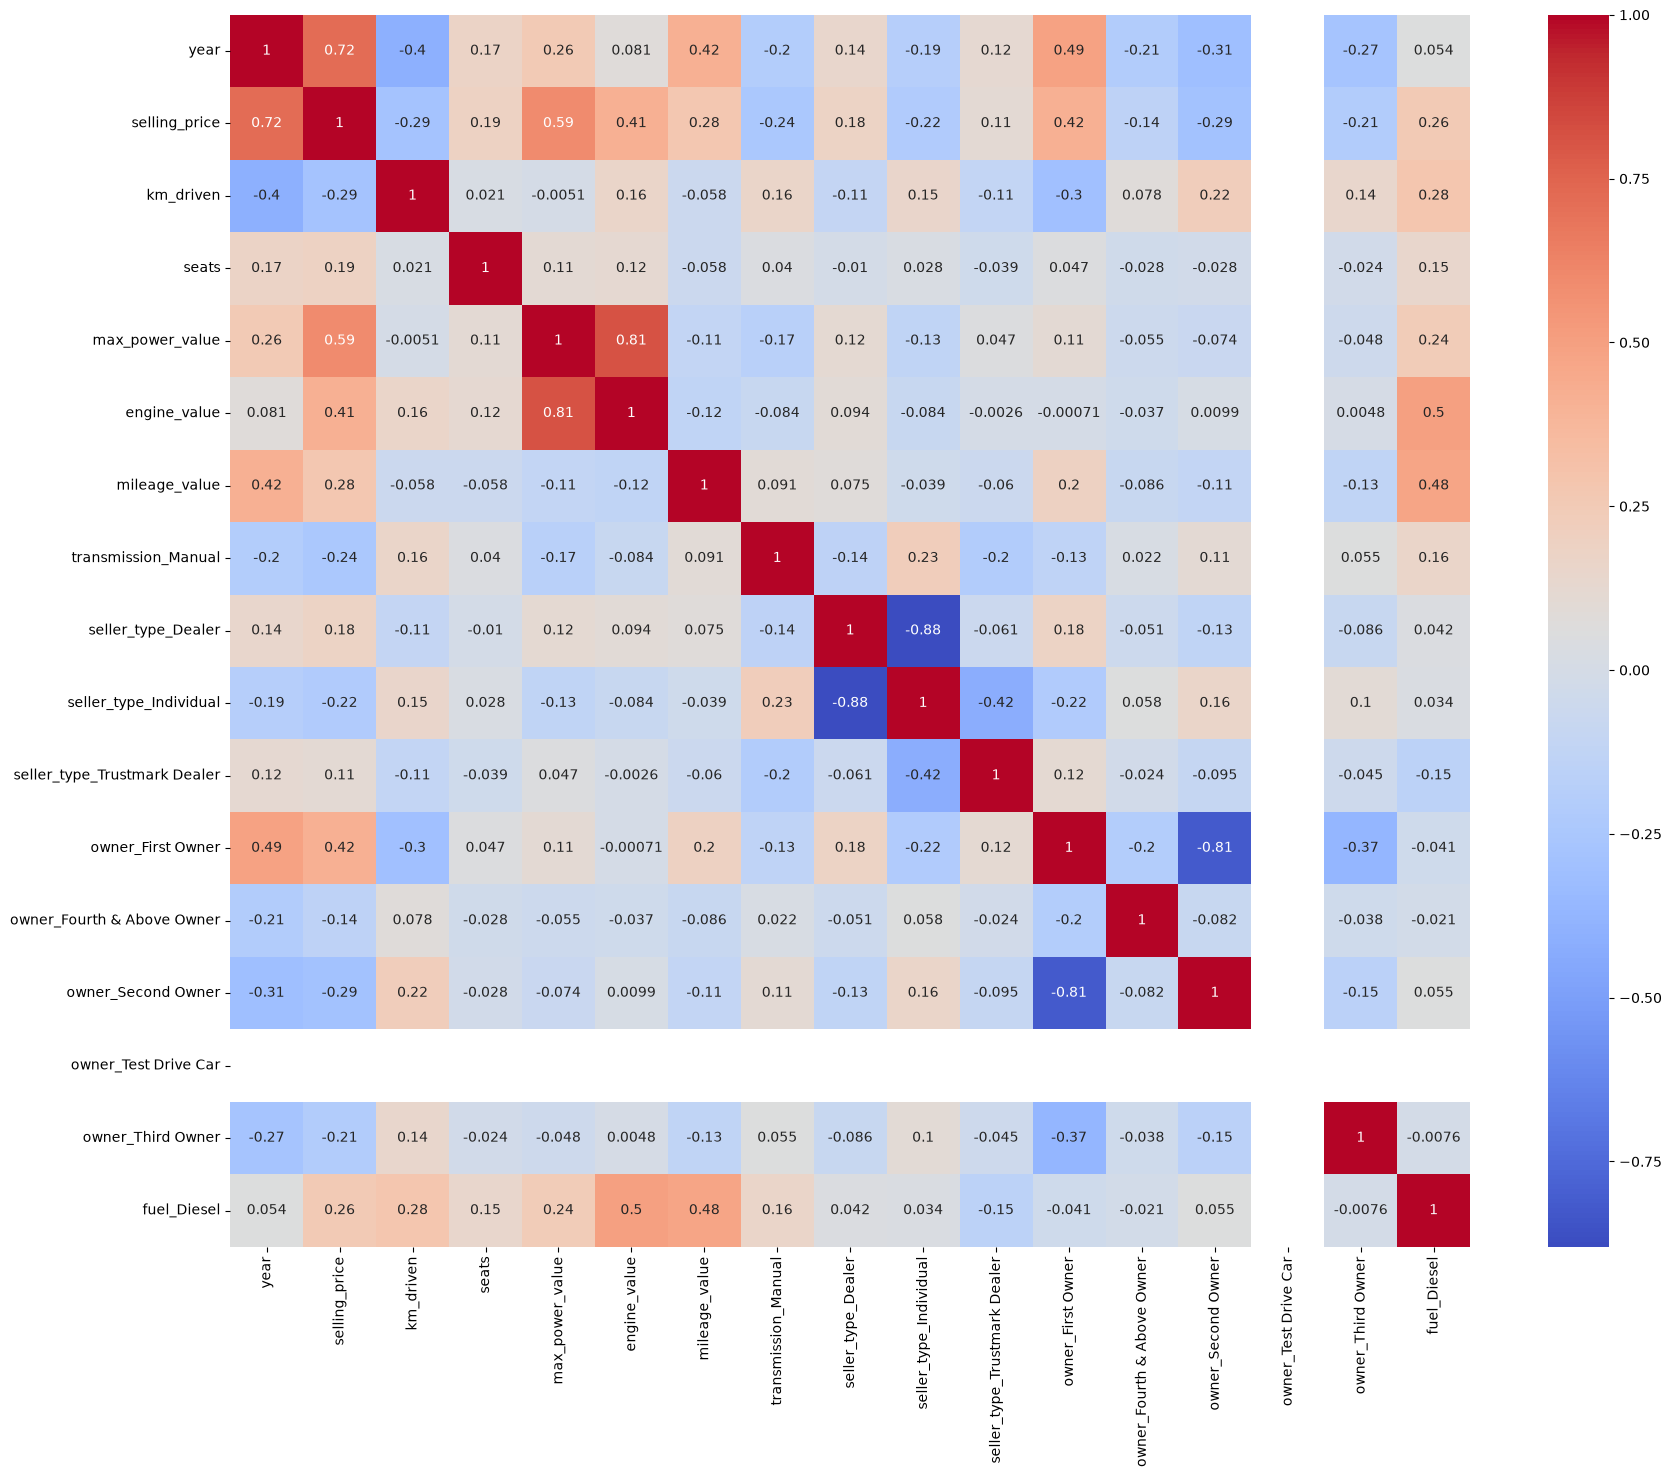

In [47]:
plt.figure(figsize=(20, 16))
sns.heatmap(data=df.corr(numeric_only=True), annot=True, cmap="coolwarm")

## Lets ***scale down features before training***

In [48]:

scaler = StandardScaler()

x = df.drop(columns="selling_price")
y = df["selling_price"]

x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=7)
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

## Training Time

Text(0, 0.5, 'predicted')

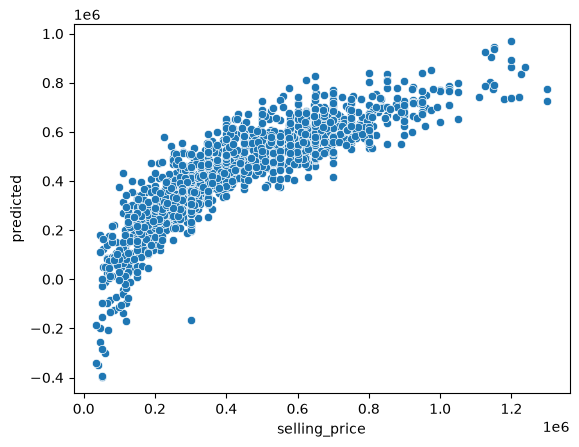

In [49]:
model = LinearRegression()
model.fit(x_train_s, y_train)

y_pred = model.predict(x_test_s)

sns.scatterplot(x=y_test, y=y_pred)
plt.ylabel("predicted")

## ***Judging time***

### first we want to see how well it did on the ***training set***

In [53]:
y_pred = model.predict(x_train_s)
r2 = r2_score(y_train, y_pred)
RMSE = np.sqrt(mean_squared_error(y_train, y_pred))

print("R2: " , r2)
print("RMSE: " , RMSE)

R2:  0.7232285976027103
RMSE:  127411.41100711444


### now the ***test set***

In [54]:
y_pred = model.predict(x_test_s)
r2 = r2_score(y_test, y_pred)
RMSE = np.sqrt(mean_squared_error(y_test, y_pred))

print("R2: " , r2)
print("RMSE: " , RMSE)

R2:  0.7406053698752109
RMSE:  123157.780367556


## which feature was the most ***important?***

In [ ]:
print(abs(pd.Series(model.coef_, index=x_train.columns)).sort_values(ascending=False))

year                            119800.740173
max_power_value                 116285.544058
fuel_Diesel                      50655.842546
engine_value                     30097.260275
transmission_Manual              18398.108365
km_driven                        16955.931112
owner_First Owner                11401.159922
owner_Second Owner                9841.851322
seats                             7789.043955
owner_Third Owner                 4757.557740
seller_type_Trustmark Dealer      4209.759013
seller_type_Individual            4137.908626
seller_type_Dealer                2360.010713
mileage_value                     1684.555210
owner_Fourth & Above Owner         494.357590
owner_Test Drive Car                 0.000000
dtype: float64


## Lets graph the results

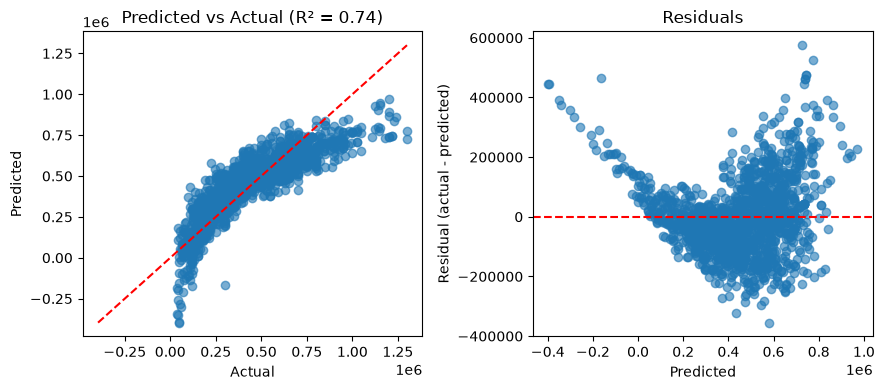

In [59]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(9, 4))

# Predicted vs actual
ax[0].scatter(y_test, y_pred, alpha=0.6)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lims, lims, "r--")          # perfect-prediction line
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
ax[0].set_title(f"Predicted vs Actual (R² = {r2_score(y_test, y_pred):.2f})")

# Residuals
ax[1].scatter(y_pred, y_test - y_pred, alpha=0.6)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals")

plt.tight_layout()
plt.savefig("model_eval.png", dpi=200)   # image you can share
plt.show()